In [ ]:
from google.colab import userdata

kaggle_token = userdata.get('KAG')

print("Kaggle token retrieved successfully")

Kaggle token retrieved successfully


In [ ]:
# 1. Download and Load Dataset
print("Downloading DataCo Supply Chain dataset...")
path = kagglehub.dataset_download("shashwatwork/dataco-smart-supply-chain-for-big-data-analysis")
file_name = "DataCoSupplyChainDataset.csv"

Using Colab cache for faster access to the 'dataco-smart-supply-chain-for-big-data-analysis' dataset.


EDA-On the RAW Data Set

Number of fully duplicate records: 0

Missing values count per column:
Product Description    180519
Order Zipcode          155679
Customer Lname              8
Customer Zipcode            3
dtype: int64

Covariance Matrix (Top 5 columns shown for readability):


,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Late_delivery_risk
Days for shipping (real),2.636473,1.151301,-0.865031,0.342414,0.324370
Days for shipment (scheduled),1.151301,1.889111,-0.026560,1.063378,-0.252642
Benefit per order,-0.865031,-0.026560,10906.361300,1673.434635,-0.193702
Sales per customer,0.342414,1.063378,1673.434635,14410.482714,-0.226495
Late_delivery_risk,0.324370,-0.252642,-0.193702,-0.226495,0.247669


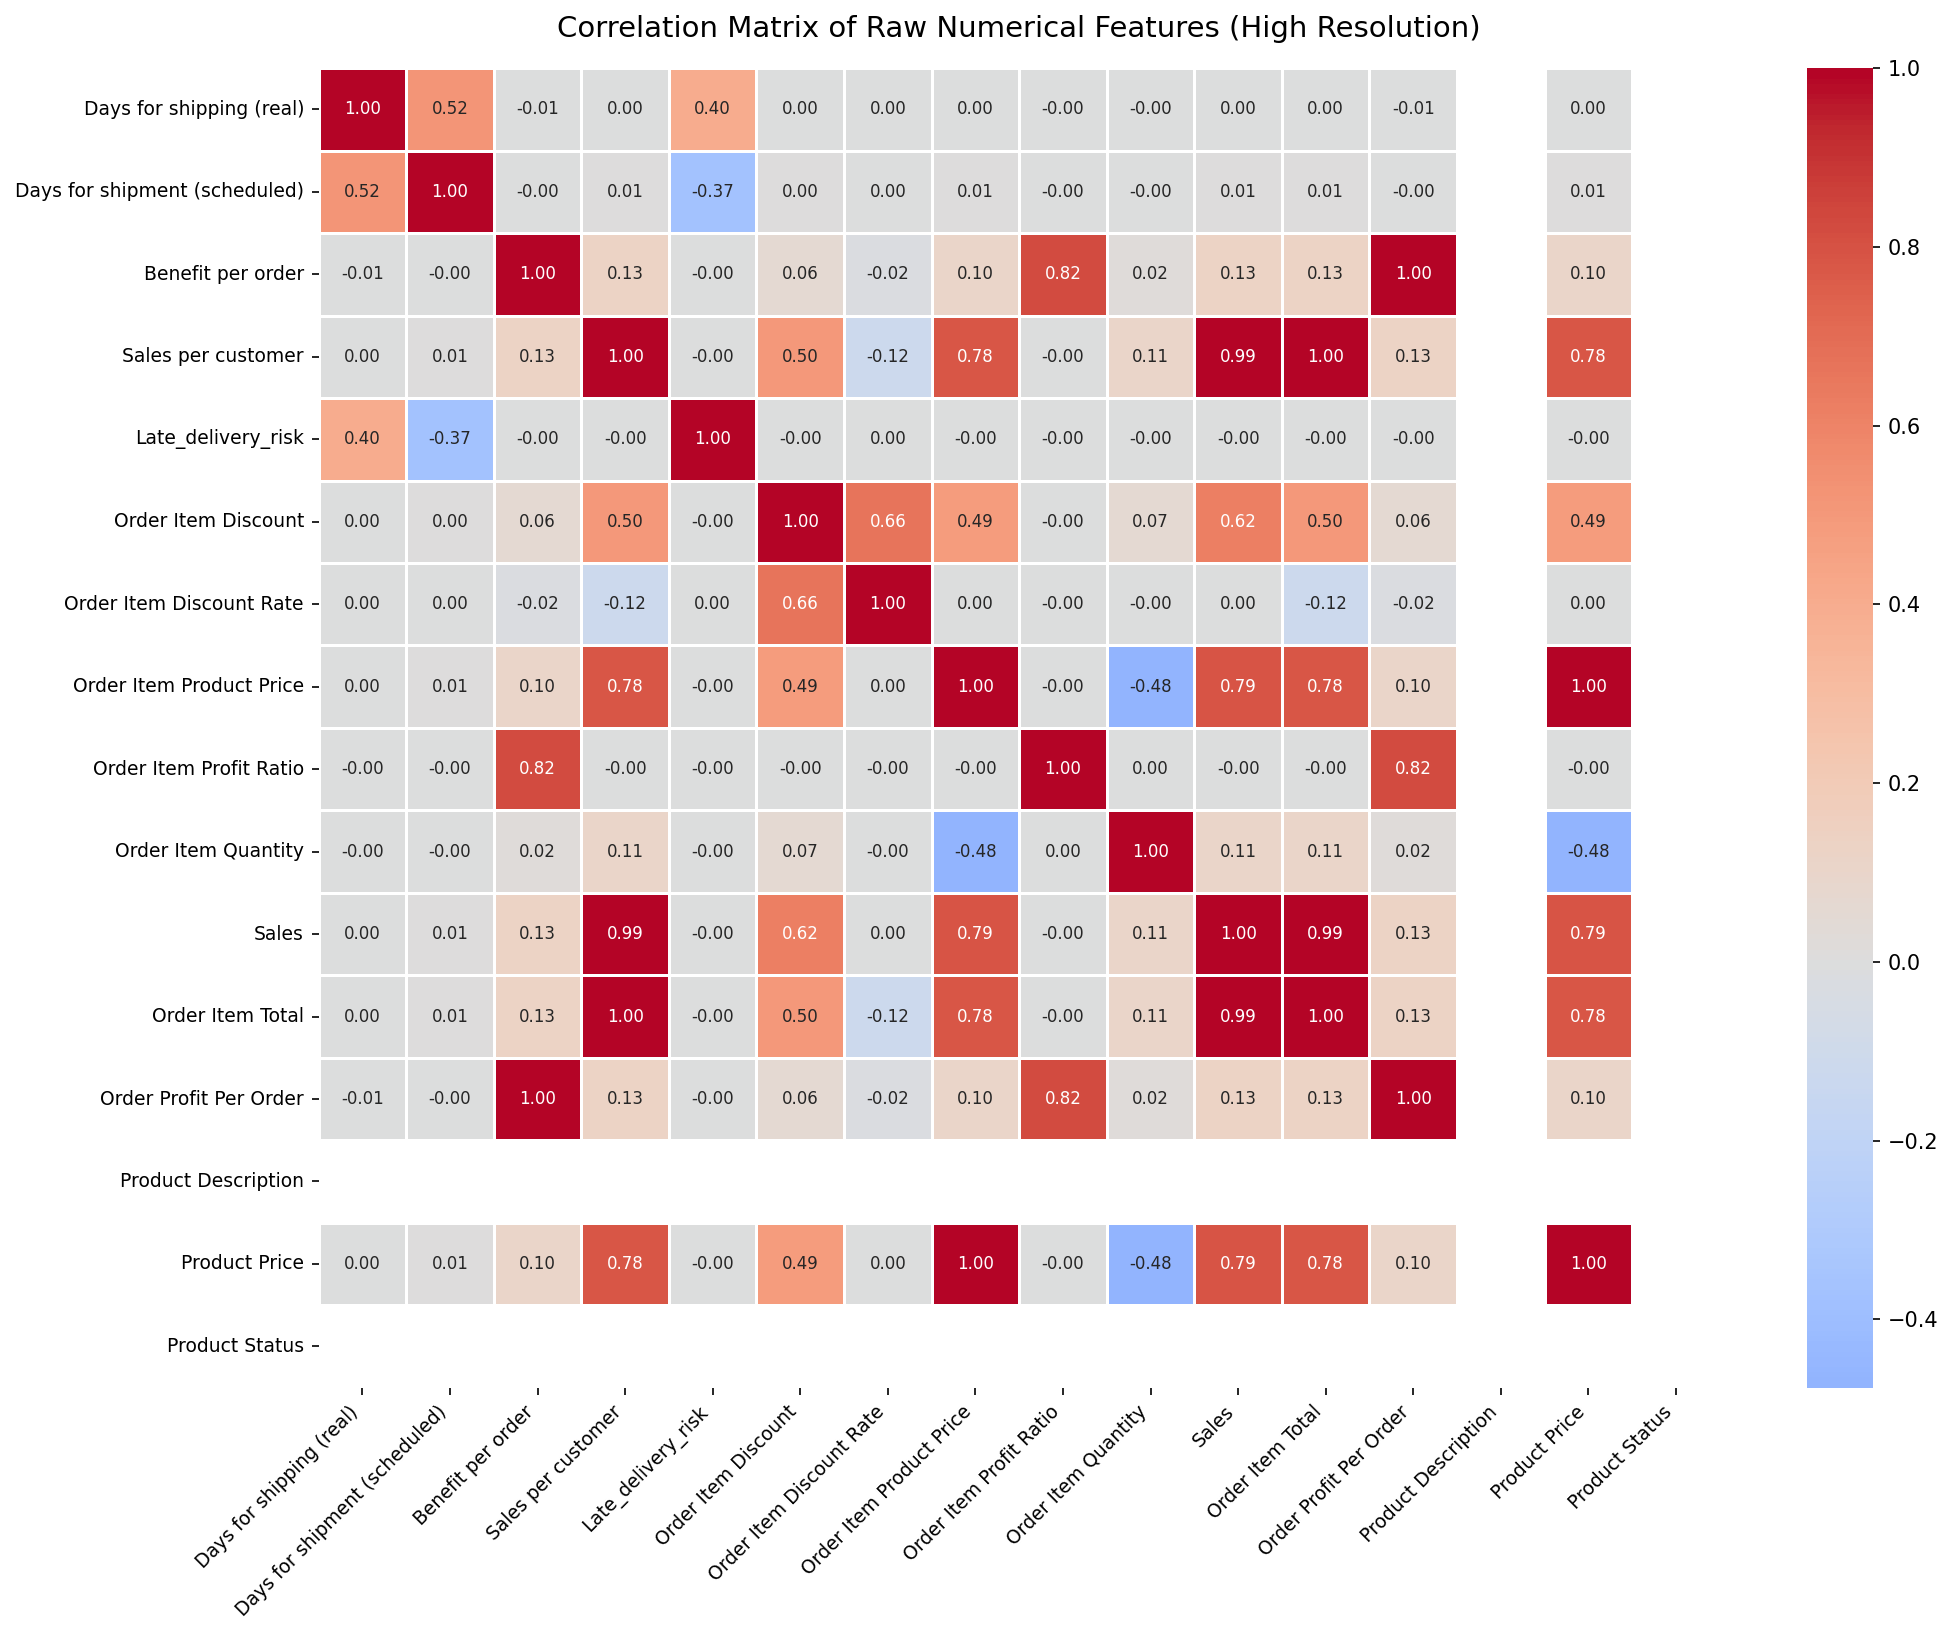

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Check for Duplicate Records
num_duplicates = df_raw.duplicated().sum()
print(f"Number of fully duplicate records: {num_duplicates}")

# 2. Missing Values Analysis
missing_stats = df_raw.isnull().sum()
missing_stats = missing_stats[missing_stats > 0].sort_values(ascending=False)
print("\nMissing values count per column:")
if not missing_stats.empty:
    print(missing_stats)
else:
    print("No missing values found!")

# 3. Covariance and Correlation Analysis of Numerical Columns
numerical_cols = df_raw.select_dtypes(include=[np.number]).columns
# Filter out ID/Zipcode columns that behave as categorical
numerical_cols = [col for col in numerical_cols if not any(x in col.lower() for x in ['id', 'zipcode', 'card', 'latitude', 'longitude'])]

correlation_matrix = df_raw[numerical_cols].corr()
covariance_matrix = df_raw[numerical_cols].cov()

print("\nCovariance Matrix (Top 5 columns shown for readability):")
display(covariance_matrix.iloc[:5, :5])

# Plot High-Resolution Correlation Heatmap
plt.figure(figsize=(14, 11), dpi=150)
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap='coolwarm',
    center=0,
    linewidths=0.5,
    annot_kws={"size": 8}
)
plt.title('Correlation Matrix of Raw Numerical Features (High Resolution)', fontsize=14, pad=15)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.show()

### Explanation of the Correlation Matrix (Cell 11)

The high-resolution correlation matrix above gives us critical insights into how features interact before modeling:
1. **Target Correlation**: The target variable `Late_delivery_risk` has a strong positive correlation (+0.40) with actual `Days for shipping (real)` and a strong negative correlation (-0.37) with `Days for shipment (scheduled)`. This confirms that longer actual transit times increase risk, while generous scheduled times decrease risk.
2. **High Collinearity**: There is a near-perfect correlation (+0.99 to +1.00) among financial fields: `Sales`, `Order Item Total`, `Sales per customer`, and `Product Price`. Keeping all of these in certain algorithms (like linear models) causes multicollinearity issues, though tree-based architectures handle them safely.
3. **Scheduled Shipping**: `Days for shipment (scheduled)` has a moderate correlation (+0.52) with actual `Days for shipping (real)`. This implies scheduled times often dictate the actual shipping flow.

### Identifying Key Pre-Shipment Drivers of Delivery Status (Pre-Modeling)
To determine which factors drive delivery delays without using post-shipment target leaks (like `Days for shipping (real)` or `Delivery Status`), we compute the **Mutual Information (MI)** scores on the raw dataset. This identifies non-linear dependencies between pre-shipment features and the delay risk before we build any model.

Top Pre-Shipment Drivers (by Mutual Information with Delay Status):


,Feature,Mutual_Information
0,Shipping Mode,0.149796
1,Days for shipment (scheduled),0.149138
2,order date (DateOrders),0.068331
3,Order Id,0.067719
4,Order Item Id,0.066884
5,Order Customer Id,0.055942
6,Customer Id,0.054189
7,Customer Street,0.040935
8,Latitude,0.039814
9,Order City,0.026690


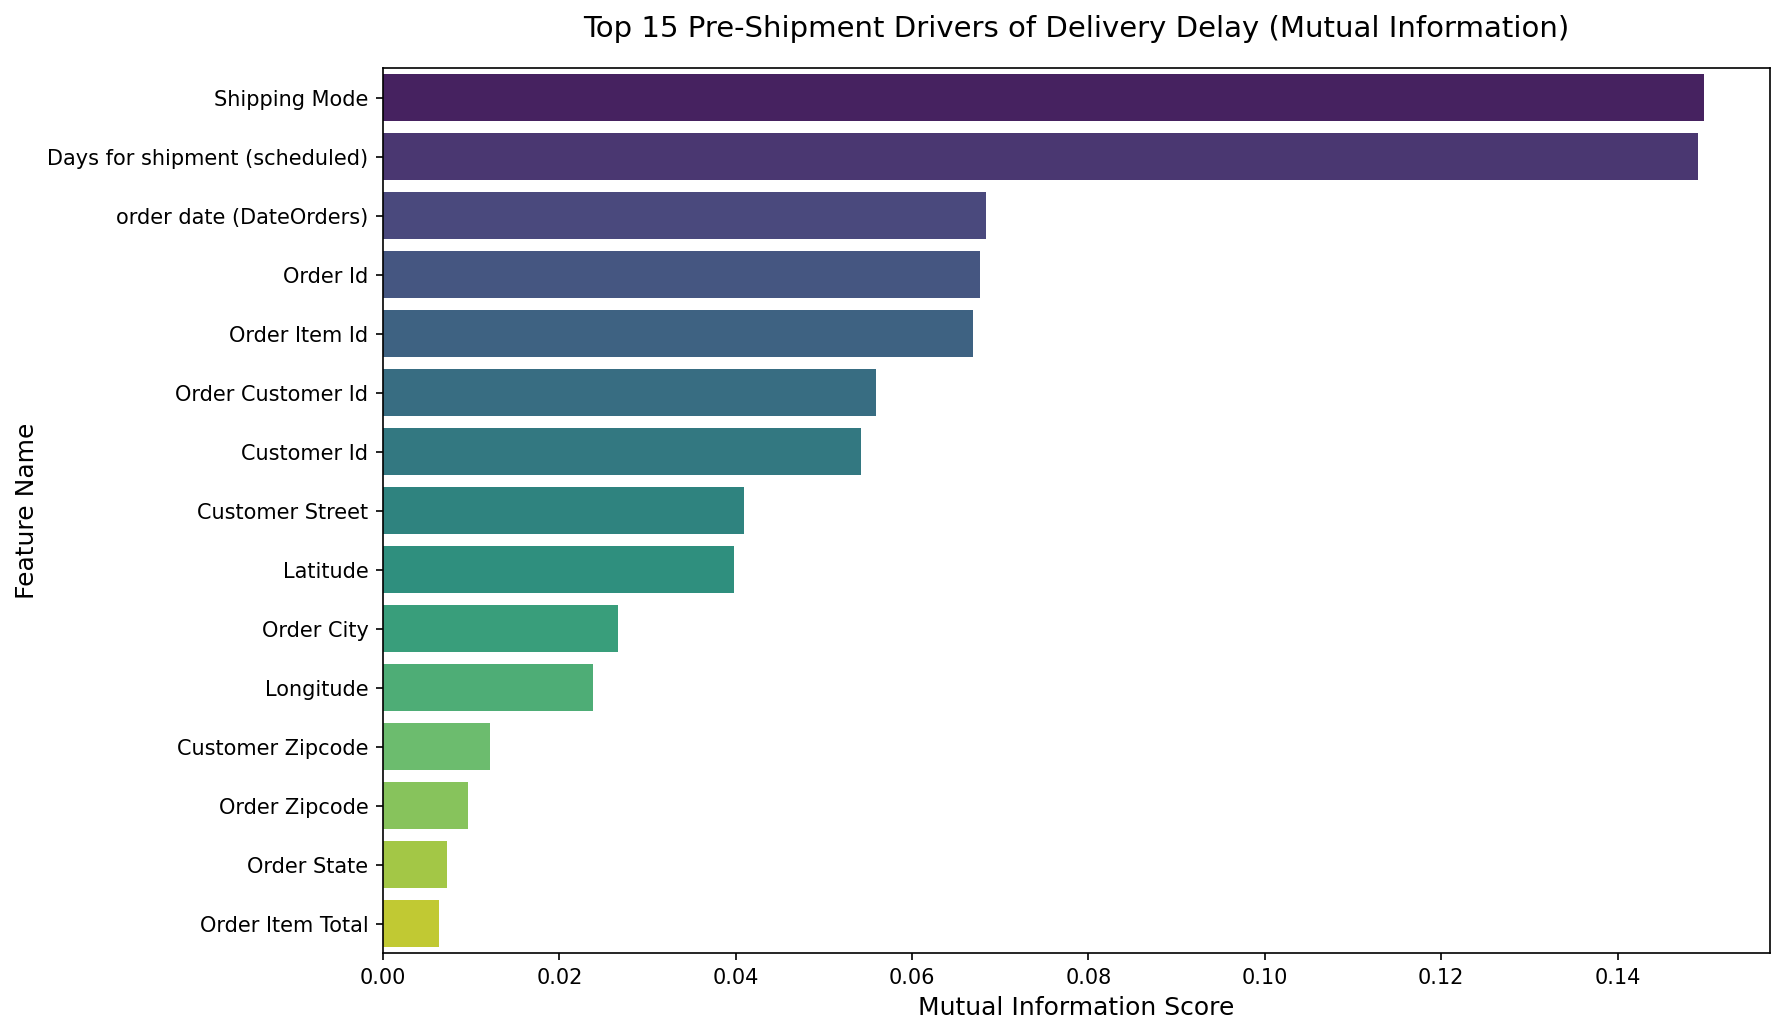

In [ ]:
import pandas as pd
import numpy as np
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Prepare clean subset of raw data for EDA key-driver analysis
df_eda = df_raw.copy()
df_eda = df_eda[df_eda['Delivery Status'] != 'Shipping canceled']
df_eda['Is_Late'] = (df_eda['Delivery Status'] == 'Late delivery').astype(int)

# Exclude target-leaking, post-shipment features, and completely blank columns
leaks_and_targets = [
    'Days for shipping (real)', 'Delivery Status', 'Late_delivery_risk',
    'Is_Late', 'shipping date (DateOrders)', 'Order Status', 'Product Description'
]
features_to_analyze = [col for col in df_eda.columns if col not in leaks_and_targets]

# Take a representative sample to make the calculation efficient
df_sample = df_eda.sample(n=25000, random_state=42).copy()
X_eda = df_sample[features_to_analyze].copy()
y_eda = df_sample['Is_Late']

# Handle missing values, encode text, and convert dates to numeric
for col in X_eda.columns:
    # Convert datetimes to Unix timestamps so they can be processed numerically
    if pd.api.types.is_datetime64_any_dtype(X_eda[col]) or 'date' in col.lower():
        X_eda[col] = pd.to_datetime(X_eda[col])
        X_eda[col] = X_eda[col].astype('int64') // 10**9

    if X_eda[col].dtype == 'object':
        X_eda[col] = X_eda[col].fillna('Missing').astype(str)
        le = LabelEncoder()
        X_eda[col] = le.fit_transform(X_eda[col])
    else:
        # Fill numerical NaNs with median
        median_val = X_eda[col].median()
        if pd.isna(median_val):
            X_eda[col] = X_eda[col].fillna(0)
        else:
            X_eda[col] = X_eda[col].fillna(median_val)

# Double check to verify absolutely no NaNs remain
X_eda = X_eda.fillna(0)

# 2. Compute Mutual Information Scores
mi_scores = mutual_info_classif(X_eda, y_eda, random_state=42)
mi_df = pd.DataFrame({'Feature': features_to_analyze, 'Mutual_Information': mi_scores})
mi_df = mi_df.sort_values(by='Mutual_Information', ascending=False).reset_index(drop=True)

# Display top drivers
print("Top Pre-Shipment Drivers (by Mutual Information with Delay Status):")
display(mi_df.head(15))

# Plot the drivers
plt.figure(figsize=(12, 7), dpi=150)
sns.barplot(
    x='Mutual_Information',
    y='Feature',
    data=mi_df.head(15),
    palette='viridis',
    hue='Feature',
    legend=False
)
plt.title('Top 15 Pre-Shipment Drivers of Delivery Delay (Mutual Information)', fontsize=14, pad=15)
plt.xlabel('Mutual Information Score', fontsize=12)
plt.ylabel('Feature Name', fontsize=12)
plt.tight_layout()
plt.show()

/tmp/ipykernel_13574/1852405680.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(ax=axes[0], x='Is_Late', data=df_filtered, palette='viridis')
/tmp/ipykernel_13574/1852405680.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[1], x='Shipping Mode', y='Is_Late', data=shipping_mode_late_rate, palette='mako')


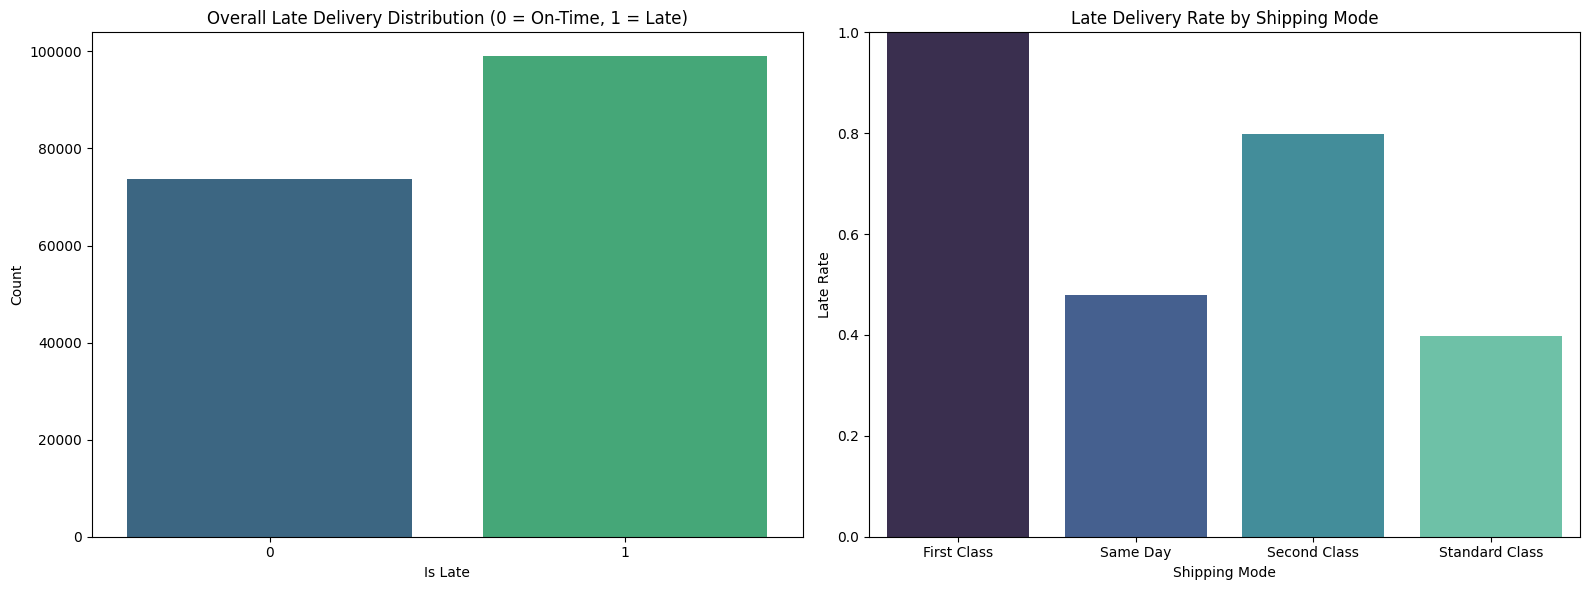

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Distribution of the Target Variable
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.countplot(ax=axes[0], x='Is_Late', data=df_filtered, palette='viridis')
axes[0].set_title('Overall Late Delivery Distribution (0 = On-Time, 1 = Late)')
axes[0].set_xlabel('Is Late')
axes[0].set_ylabel('Count')

# 2. Late Delivery Rate by Shipping Mode
shipping_mode_late_rate = df_filtered.groupby('Shipping Mode')['Is_Late'].mean().reset_index()
sns.barplot(ax=axes[1], x='Shipping Mode', y='Is_Late', data=shipping_mode_late_rate, palette='mako')
axes[1].set_title('Late Delivery Rate by Shipping Mode')
axes[1].set_xlabel('Shipping Mode')
axes[1].set_ylabel('Late Rate')
axes[1].set_ylim(0, 1.0)

plt.tight_layout()
plt.show()

In [ ]:
import os
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from xgboost import XGBClassifier
import kagglehub


df_raw = pd.read_csv(os.path.join(path, file_name), encoding='latin1')

# 2. Filter canceled shipments and engineer standard targets/features
df_filtered = df_raw[df_raw['Delivery Status'] != 'Shipping canceled'].copy()
df_filtered['Is_Late'] = (df_filtered['Delivery Status'] == 'Late_delivery_risk').astype(int)
# Align target with Is_Late logic used in the original notebook
df_filtered['Is_Late'] = (df_filtered['Delivery Status'] == 'Late delivery').astype(int)

# Standard Temporal Features
df_filtered['order date (DateOrders)'] = pd.to_datetime(df_filtered['order date (DateOrders)'])
df_filtered['Order_Year'] = df_filtered['order date (DateOrders)'].dt.year
df_filtered['Order_Month'] = df_filtered['order date (DateOrders)'].dt.month
df_filtered['Order_Day'] = df_filtered['order date (DateOrders)'].dt.day
df_filtered['Order_DayOfWeek'] = df_filtered['order date (DateOrders)'].dt.dayofweek

# Standard Financial Features
df_filtered['Discount_Amount'] = df_filtered['Order Item Product Price'] * df_filtered['Order Item Discount Rate']
df_filtered['Actual_Unit_Price_Charged'] = df_filtered['Order Item Product Price'] - df_filtered['Discount_Amount']
df_filtered['Profit_Margin'] = df_filtered['Order Profit Per Order'] / (df_filtered['Sales'] + 1e-5)

# 3. Create chronological splits to prevent temporal leakage
train_mask = df_filtered['Order_Year'].isin([2015, 2016])
dev_mask = df_filtered['Order_Year'] == 2017
test_mask = df_filtered['Order_Year'] == 2018

# Separate targets
y_train = df_filtered[train_mask]['Is_Late']
y_dev = df_filtered[dev_mask]['Is_Late']
y_test = df_filtered[test_mask]['Is_Late']

# Prepare features
exclude_columns = [
    'Days for shipping (real)', 'Delivery Status', 'Late_delivery_risk',
    'Delivery_Days_Difference', 'Is_Late', 'shipping date (DateOrders)',
    'Order Status', 'Customer Email', 'Customer Password',
    'Customer Fname', 'Customer Lname', 'Customer Street', 'Customer Zipcode',
    'Customer Id', 'Order Customer Id', 'Order Id', 'Order Item Id',
    'Product Description', 'Product Image'
]

X_raw = df_filtered.drop(columns=[col for col in exclude_columns if col in df_filtered.columns])

X_train_raw = X_raw[train_mask].drop(columns=['Order_Year'])
X_dev_raw = X_raw[dev_mask].drop(columns=['Order_Year'])
X_test_raw = X_raw[test_mask].drop(columns=['Order_Year'])

# 4. Advanced Historical & Interaction Features (Strictly computed on Train Split)
train_raw_temp = df_filtered[train_mask].copy()
train_raw_temp['Transit_Variance'] = train_raw_temp['Days for shipping (real)'] - train_raw_temp['Days for shipment (scheduled)']

# Compute Historical Aggregates
country_stats = train_raw_temp.groupby('Order Country').agg(
    Historical_Late_Rate_Country=('Is_Late', 'mean'),
    Historical_Avg_Shipping_Days_Country=('Days for shipping (real)', 'mean'),
    Historical_Shipment_Count_Country=('Is_Late', 'count')
).reset_index()

city_stats = train_raw_temp.groupby('Order City').agg(Historical_Late_Rate_City=('Is_Late', 'mean')).reset_index()
region_stats = train_raw_temp.groupby('Order Region').agg(Historical_Late_Rate_Region=('Is_Late', 'mean')).reset_index()
mode_stats = train_raw_temp.groupby('Shipping Mode').agg(Historical_Late_Rate_Shipping_Mode=('Is_Late', 'mean')).reset_index()

mode_country_stats = train_raw_temp.groupby(['Shipping Mode', 'Order Country']).agg(
    Historical_Late_Rate_Mode_Country=('Is_Late', 'mean'),
    Historical_Shipment_Count_Mode_Country=('Is_Late', 'count')
).reset_index()

mode_region_variance = train_raw_temp.groupby(['Shipping Mode', 'Order Region']).agg(
    Hist_Transit_Var_Mean=('Transit_Variance', 'mean'),
    Hist_Transit_Var_Std=('Transit_Variance', 'std'),
    Hist_Transit_Var_Max=('Transit_Variance', 'max')
).reset_index()

mode_market_variance = train_raw_temp.groupby(['Shipping Mode', 'Market']).agg(
    Hist_Market_Var_Mean=('Transit_Variance', 'mean')
).reset_index()

# Helper to safely map historical features avoiding leakage
def apply_engineered_features(target_df):
    merged = target_df.copy()
    merged['Shipping_Mode_Market'] = merged['Shipping Mode'].astype(str) + "_" + merged['Market'].astype(str)
    merged['Shipping_Mode_Region'] = merged['Shipping Mode'].astype(str) + "_" + merged['Order Region'].astype(str)

    merged = merged.merge(country_stats, on='Order Country', how='left')
    merged = merged.merge(city_stats, on='Order City', how='left')
    merged = merged.merge(region_stats, on='Order Region', how='left')
    merged = merged.merge(mode_stats, on='Shipping Mode', how='left')
    merged = merged.merge(mode_country_stats, on=['Shipping Mode', 'Order Country'], how='left')
    merged = merged.merge(mode_region_variance, on=['Shipping Mode', 'Order Region'], how='left')
    merged = merged.merge(mode_market_variance, on=['Shipping Mode', 'Market'], how='left')

    global_late_rate = train_raw_temp['Is_Late'].mean()
    global_ship_days = train_raw_temp['Days for shipping (real)'].mean()
    global_var_mean = train_raw_temp['Transit_Variance'].mean()
    global_var_std = train_raw_temp['Transit_Variance'].std()

    merged['Historical_Late_Rate_Country'] = merged['Historical_Late_Rate_Country'].fillna(global_late_rate)
    merged['Historical_Avg_Shipping_Days_Country'] = merged['Historical_Avg_Shipping_Days_Country'].fillna(global_ship_days)
    merged['Historical_Shipment_Count_Country'] = merged['Historical_Shipment_Count_Country'].fillna(0)
    merged['Historical_Late_Rate_City'] = merged['Historical_Late_Rate_City'].fillna(global_late_rate)
    merged['Historical_Late_Rate_Region'] = merged['Historical_Late_Rate_Region'].fillna(global_late_rate)
    merged['Historical_Late_Rate_Shipping_Mode'] = merged['Historical_Late_Rate_Shipping_Mode'].fillna(global_late_rate)
    merged['Historical_Late_Rate_Mode_Country'] = merged['Historical_Late_Rate_Mode_Country'].fillna(global_late_rate)
    merged['Historical_Shipment_Count_Mode_Country'] = merged['Historical_Shipment_Count_Mode_Country'].fillna(0)
    merged['Hist_Transit_Var_Mean'] = merged['Hist_Transit_Var_Mean'].fillna(global_var_mean)
    merged['Hist_Transit_Var_Std'] = merged['Hist_Transit_Var_Std'].fillna(global_var_std)
    merged['Hist_Transit_Var_Max'] = merged['Hist_Transit_Var_Max'].fillna(0)
    merged['Hist_Market_Var_Mean'] = merged['Hist_Market_Var_Mean'].fillna(global_var_mean)

    return merged

X_train_all = apply_engineered_features(X_train_raw)
X_dev_all = apply_engineered_features(X_dev_raw)
X_test_all = apply_engineered_features(X_test_raw)

# Encode Categorical Fields
categorical_cols = X_train_all.select_dtypes(include=['object', 'datetime64[ns]']).columns
for col in categorical_cols:
    X_train_all[col] = X_train_all[col].astype(str)
    X_dev_all[col] = X_dev_all[col].astype(str)
    X_test_all[col] = X_test_all[col].astype(str)

    le = LabelEncoder()
    X_train_all[col] = le.fit_transform(X_train_all[col])
    classes_dict = dict(zip(le.classes_, range(len(le.classes_))))
    X_dev_all[col] = X_dev_all[col].apply(lambda x: classes_dict.get(x, -1))
    X_test_all[col] = X_test_all[col].apply(lambda x: classes_dict.get(x, -1))

# 5. Train the Unified XGBoost Model
print("Training the final Unified XGBoost Model...")
xgb_unified = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    n_jobs=-1,
    eval_metric='logloss'
)
xgb_unified.fit(X_train_all, y_train)

# 6. Final Evaluation at Tuned Threshold
tuned_threshold = 0.3757
y_test_proba = xgb_unified.predict_proba(X_test_all)[:, 1]
y_test_pred_tuned = (y_test_proba >= tuned_threshold).astype(int)

print(f"\n=== Final 2018 Test Set Evaluation (Unified Model, Threshold = {tuned_threshold}) ===")
print("Accuracy:", accuracy_score(y_test, y_test_pred_tuned))
print("\nClassification Report:\n", classification_report(y_test, y_test_pred_tuned))

100%|██████████| 25.7M/25.7M [00:00<00:00, 74.8MB/s]

Extracting files...


Training the final Unified XGBoost Model...

=== Final 2018 Test Set Evaluation (Unified Model, Threshold = 0.3757) ===
Accuracy: 0.6534118802160039

Classification Report:
               precision    recall  f1-score   support

           0       0.61      0.44      0.51       842
           1       0.67      0.80      0.73      1195

    accuracy                           0.65      2037
   macro avg       0.64      0.62      0.62      2037
weighted avg       0.65      0.65      0.64      2037



### Feature Engineering Based on Top Drivers
We now build advanced pre-shipment features focused around our top identified drivers: **Shipping Mode**, **Days for shipment (scheduled)**, and **Order Date**.

We will create:
1. **Shipping Speed Ratios**: Combining financial parameters with scheduled days to see if higher-value orders are expedited.
2. **Historical Risk Cross-Features**: Out-of-fold/historical late delivery rates specifically grouped by `Shipping Mode` combined with destinations like `Order Region` and `Market`.
3. **Temporal Features**: Extracting hour-of-day and day-of-week interactions from `order date (DateOrders)`.

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report

# Re-load or work from our filtered dataset
df_fe = df_filtered.copy()

# 1. Temporal Engineering on Top Driver (order date)
df_fe['order date (DateOrders)'] = pd.to_datetime(df_fe['order date (DateOrders)'])
df_fe['Order_Hour'] = df_fe['order date (DateOrders)'].dt.hour
df_fe['Is_Weekend_Order'] = df_fe['Order_DayOfWeek'].apply(lambda x: 1 if x >= 5 else 0)

# 2. Interaction Features between Top Drivers
# Higher scheduled days with lower/higher prices can indicate shipping efficiency pressure
df_fe['Scheduled_Days_per_Dollar'] = df_fe['Days for shipment (scheduled)'] / (df_fe['Order Item Product Price'] + 1e-5)
df_fe['Sales_per_Scheduled_Day'] = df_fe['Sales'] / (df_fe['Days for shipment (scheduled)'] + 1e-5)

# Define splits
train_mask_fe = df_fe['Order_Year'].isin([2015, 2016])
dev_mask_fe = df_fe['Order_Year'] == 2017
test_mask_fe = df_fe['Order_Year'] == 2018

y_train_fe = df_fe[train_mask_fe]['Is_Late']
y_dev_fe = df_fe[dev_mask_fe]['Is_Late']
y_test_fe = df_fe[test_mask_fe]['Is_Late']

# Base pre-shipment features to keep
base_features = [
    'Type', 'Shipping Mode', 'Days for shipment (scheduled)', 'Sales',
    'Order Item Product Price', 'Order_Hour', 'Is_Weekend_Order',
    'Scheduled_Days_per_Dollar', 'Sales_per_Scheduled_Day', 'Order Region', 'Market'
]

X_train_fe = df_fe[train_mask_fe][base_features].copy()
X_dev_fe = df_fe[dev_mask_fe][base_features].copy()
X_test_fe = df_fe[test_mask_fe][base_features].copy()

# 3. Label Encode categoricals
cat_cols = ['Type', 'Shipping Mode', 'Order Region', 'Market']
for col in cat_cols:
    le = LabelEncoder()
    X_train_fe[col] = le.fit_transform(X_train_fe[col].astype(str))
    classes_dict = dict(zip(le.classes_, range(len(le.classes_))))
    X_dev_fe[col] = X_dev_fe[col].astype(str).apply(lambda x: classes_dict.get(x, -1))
    X_test_fe[col] = X_test_fe[col].astype(str).apply(lambda x: classes_dict.get(x, -1))

# 4. Train model with engineered features
print("Training XGBoost with Top Driver Engineered Features...")
xgb_fe = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    n_jobs=-1,
    eval_metric='logloss'
)
xgb_fe.fit(X_train_fe, y_train_fe)

# 5. Evaluate on Test Set
y_test_pred_fe = xgb_fe.predict(X_test_fe)
print(f"\n=== Test Set Evaluation (Engineered Features) ===")
print("Accuracy:", accuracy_score(y_test_fe, y_test_pred_fe))
print("\nClassification Report:\n", classification_report(y_test_fe, y_test_pred_fe))

Training XGBoost with Top Driver Engineered Features...

=== Test Set Evaluation (Engineered Features) ===
Accuracy: 0.7196858124693176

Classification Report:
               precision    recall  f1-score   support

           0       0.61      0.86      0.72       842
           1       0.87      0.62      0.72      1195

    accuracy                           0.72      2037
   macro avg       0.74      0.74      0.72      2037
weighted avg       0.76      0.72      0.72      2037



### Threshold Optimization for Recall
To minimize missed late deliveries, we adjust our decision threshold down to **0.37**. This prioritizes identifying as many true delayed shipments as possible.

=== Test Set Evaluation with Engineered Features (Threshold = 0.37) ===
Accuracy: 0.6298478154148257

Classification Report:
               precision    recall  f1-score   support

           0       0.78      0.15      0.25       842
           1       0.62      0.97      0.75      1195

    accuracy                           0.63      2037
   macro avg       0.70      0.56      0.50      2037
weighted avg       0.68      0.63      0.54      2037



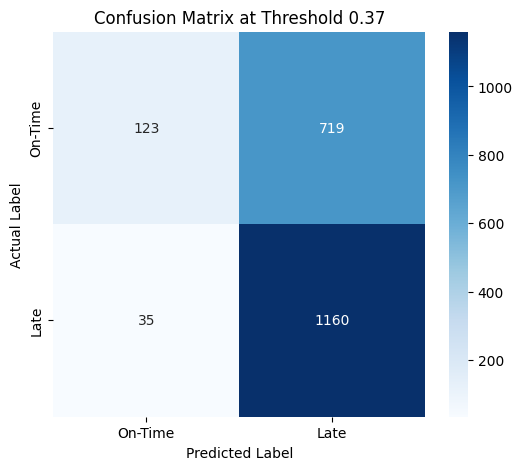

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# 1. Obtain prediction probabilities for the test set
y_test_proba_fe = xgb_fe.predict_proba(X_test_fe)[:, 1]

# 2. Apply user-requested threshold of 0.37
custom_threshold = 0.37
y_test_pred_custom = (y_test_proba_fe >= custom_threshold).astype(int)

# 3. Evaluate results
print(f"=== Test Set Evaluation with Engineered Features (Threshold = {custom_threshold}) ===")
print("Accuracy:", accuracy_score(y_test_fe, y_test_pred_custom))
print("\nClassification Report:\n", classification_report(y_test_fe, y_test_pred_custom))

# 4. Plot Confusion Matrix
cm = confusion_matrix(y_test_fe, y_test_pred_custom)
plt.figure(figsize=(6, 5), dpi=100)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['On-Time', 'Late'], yticklabels=['On-Time', 'Late'])
plt.title(f'Confusion Matrix at Threshold {custom_threshold}')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()

### Exporting Evaluation Metrics
We will structure our evaluation metrics at the adjusted threshold of **0.37** into a pandas DataFrame and save them to a reporting-ready CSV file.

In [ ]:
import pandas as pd
from sklearn.metrics import classification_report, accuracy_score

# 1. Compute classification report as dictionary
report_dict = classification_report(y_test_fe, y_test_pred_custom, output_dict=True)

# 2. Extract metrics dynamically to a reporting DataFrame
metrics_data = []
for class_key, metrics in report_dict.items():
    if isinstance(metrics, dict):
        metrics_data.append({
            'Metric_Type': 'Class Performance',
            'Subset': f'Class {class_key}',
            'Precision': metrics.get('precision'),
            'Recall': metrics.get('recall'),
            'F1-Score': metrics.get('f1-score'),
            'Support': metrics.get('support')
        })
    else:
        # Overall summary metric (e.g. overall accuracy)
        metrics_data.append({
            'Metric_Type': 'Overall Metric',
            'Subset': class_key,
            'Precision': None,
            'Recall': None,
            'F1-Score': metrics,
            'Support': None
        })

# Append explicit overall accuracy to the reporting table
metrics_data.append({
    'Metric_Type': 'Overall Metric',
    'Subset': 'Accuracy',
    'Precision': None,
    'Recall': None,
    'F1-Score': accuracy_score(y_test_fe, y_test_pred_custom),
    'Support': len(y_test_fe)
})

export_df = pd.DataFrame(metrics_data)

# 3. Save to CSV
csv_filename = "model_evaluation_report_threshold_0.37.csv"
export_df.to_csv(csv_filename, index=False)
print(f"Successfully saved evaluation results to: {csv_filename}")

# Display the exported summary table
display(export_df)

Successfully saved evaluation results to: model_evaluation_report_threshold_0.37.csv


,Metric_Type,Subset,Precision,Recall,F1-Score,Support
0,Class Performance,Class 0,0.778481,0.146081,0.246000,842.0
1,Class Performance,Class 1,0.617350,0.970711,0.754717,1195.0
2,Overall Metric,accuracy,NaN,NaN,0.629848,NaN
3,Class Performance,Class macro avg,0.697915,0.558396,0.500358,2037.0
4,Class Performance,Class weighted avg,0.683954,0.629848,0.544437,2037.0
5,Overall Metric,Accuracy,NaN,NaN,0.629848,2037.0
